# Generator comparison pilot

We compare three ECG generation approaches using matched four-class pilot pools to select the most promising generator for subsequent large-scale generation.

This is **not** the Week 5 quality-filtering experiment. No MMD filter, no real-vs-synthetic classifier, no CNN-LSTM retrain.

## 1. Comparison objective

In [1]:
print("Matched 128-sample (32/class) pilot pools.")
print("Select ONE generator for later large-scale generation.")
print("Do not claim SOTA from n=128.")

Matched 128-sample (32/class) pilot pools.
Select ONE generator for later large-scale generation.
Do not claim SOTA from n=128.


## 2. Environment

In [2]:
import json, shutil, sys, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

plt.rcParams.update({"figure.figsize": (11, 3.2), "font.size": 10})

print("python", sys.version.split()[0])
print("torch", torch.__version__)
print("cuda", torch.cuda.is_available())
if not torch.cuda.is_available():
    raise RuntimeError("CUDA required for SSSD sampling.")
print("gpu", torch.cuda.get_device_name(0))
print("vram_gb", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))

python 3.14.2
torch 2.11.0+cu128
cuda True
gpu NVIDIA GeForce RTX 3050 Laptop GPU
vram_gb 4.0


## 3. Shared dataset (train only)

In [3]:
from synthetic_generation.config import CLASS_ORDER, DATA_DIR, WAVENET_4GB
from synthetic_generation.leads import LEAD_ORDER_12
from synthetic_generation.model import SSSD_ECG
from synthetic_generation.sample import generate_class_batch, metadata_rows
from synthetic_generation.utils import count_params
from generator_comparison.eval_metrics import summarize_generator, lead_ii_hr, pairwise_corr

ROOT = Path("generator_comparison")
for p in [ROOT/"sssd", ROOT/"transdiff", ROOT/"sediff", ROOT/"comparison_results", ROOT/"plots", ROOT/"metadata"]:
    p.mkdir(parents=True, exist_ok=True)

X_train = np.load(DATA_DIR / "X_train.npy")
y_train = np.load(DATA_DIR / "y_train.npy")
cfg = json.loads((DATA_DIR / "dataset_config.json").read_text(encoding="utf-8"))

print("X_train", X_train.shape, X_train.dtype)
print("y_train", y_train.shape, y_train.dtype)
print("counts", {CLASS_ORDER[i]: int((y_train==i).sum()) for i in range(4)})
print("fs", cfg["sampling_rate_hz"], "leads", cfg["lead_order"])
print("val/test files loaded?", False)
assert cfg["lead_order"] == LEAD_ORDER_12
assert X_train.shape == (13811, 1000, 12)

CUDA extension for cauchy multiplication not found. Install by going to extensions/cauchy/ and running `python setup.py install`. This should speed up end-to-end training by 10-50%


Falling back on slow Cauchy kernel. Install at least one of pykeops or the CUDA extension for efficiency.


X_train (13811, 1000, 12) float32
y_train (13811,) int64
counts {'SR': 11741, 'AFIB': 1056, 'STACH': 568, 'SBRAD': 446}
fs 100 leads ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
val/test files loaded? False


## 4. Generator A — SSSD-ECG (adapted)

Existing Week 4 checkpoint trained from scratch on `X_train`/`y_train` only. Generate a **new balanced** 32/32/32/32 pool (not the Week 4 16/32/32/48 pool). Seed = 42. Do not overwrite `synthetic_data/`.

In [4]:
SSSD_SEED = 42
device = torch.device("cuda")
ckpt_src = Path("synthetic_generation/checkpoints/full_last.pt")
ckpt = torch.load(ckpt_src, map_location=device)
net = SSSD_ECG(**ckpt["wavenet_config"]).to(device)
net.load_state_dict(ckpt["model_state_dict"])
net.eval()
n_params = count_params(net)
print("params", n_params)
print("wavenet", {k: ckpt["wavenet_config"][k] for k in ("num_res_layers","res_channels","label_embed_classes")})
print("train_cfg", ckpt.get("train_cfg"))

hist = json.loads(Path("synthetic_generation/history.json").read_text(encoding="utf-8"))
full_h = hist["full"]
train_sec = full_h["history"][-1]["sec"]
peak_gb = full_h["peak_gb"]
print("week4_full_iters", full_h["history"][-1]["iter"], "sec", round(train_sec,1), "peak_gb", round(peak_gb,3))

xs, ys = [], []
torch.cuda.reset_peak_memory_stats()
t0 = time.time()
for cid, name in enumerate(CLASS_ORDER):
    x = generate_class_batch(net, cid, 32, device, batch_size=1, seed=SSSD_SEED)
    print(name, x.shape, np.isfinite(x).all())
    xs.append(x)
    ys.append(np.full(32, cid, dtype=np.int64))
sssd_sec = time.time() - t0
sssd_gen_gb = torch.cuda.max_memory_allocated() / 1024**3
X_sssd = np.concatenate(xs, 0).astype(np.float32)
y_sssd = np.concatenate(ys, 0)
print("X_sssd", X_sssd.shape, "gen_sec", round(sssd_sec,1), "gen_peak_gb", round(sssd_gen_gb,3))

dest = ROOT / "sssd"
np.save(dest / "X_synthetic.npy", X_sssd)
np.save(dest / "y_synthetic.npy", y_sssd)
meta = metadata_rows(y_sssd)
meta["generator"] = "SSSD-ECG-adapted"
meta["seed"] = SSSD_SEED
meta["pilot"] = "comparison_32x4"
meta.to_csv(dest / "metadata.csv", index=False)
shutil.copy2(ckpt_src, dest / "checkpoint.pt")
(dest / "config.json").write_text(json.dumps({
    "generator": "SSSD-ECG-adapted",
    "source": "https://github.com/AI4HealthUOL/SSSD-ECG",
    "seed": SSSD_SEED,
    "train_only": True,
    "wavenet_used": ckpt["wavenet_config"],
    "train_cfg": ckpt.get("train_cfg"),
    "n_params": n_params,
    "week4_train_sec": train_sec,
    "week4_peak_gb": peak_gb,
    "gen_sec": sssd_sec,
    "gen_peak_gb": sssd_gen_gb,
    "counts": {CLASS_ORDER[i]: 32 for i in range(4)},
    "lead_order": LEAD_ORDER_12,
    "independent_leads": ["I","II","V1","V2","V3","V4","V5","V6"],
    "reconstruction": "III=II-I; aVR=-(I+II)/2; aVL=I-II/2; aVF=II-I/2",
    "note": "Width 8x64 (not published 36x256) due to 4 GB VRAM. AMP off.",
}, indent=2), encoding="utf-8")
shutil.copy2("synthetic_generation/history.json", dest / "history.json")
print("saved", dest)

C:\Users\Shivank\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\nn\utils\weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


C:\Users\Shivank\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\nn\utils\weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


params 1528072
wavenet {'num_res_layers': 8, 'res_channels': 64, 'label_embed_classes': 4}
train_cfg {'n_iters': 4000, 'batch_size': 1, 'learning_rate': 0.0002, 'log_every': 50, 'ckpt_every': 1000, 'use_amp': False}
week4_full_iters 4000 sec 405.2 peak_gb 0.983


SR (32, 1000, 12) True


AFIB (32, 1000, 12) True


STACH (32, 1000, 12) True


SBRAD (32, 1000, 12) True
X_sssd (128, 1000, 12) gen_sec 950.9 gen_peak_gb 0.146
saved generator_comparison\sssd


## 5. Generator B — TransDiffECG

**Stopped.** No public implementation was found. PubMed: [TransDiffECG](https://pubmed.ncbi.nlm.nih.gov/41161556/) (QTDB/LUDB; transformer diffusion). GitHub search for `TransDiffECG` does not yield an ECG generator repo. The similarly named [TransDiff/TransDiff](https://github.com/TransDiff/TransDiff) is ImageNet image generation, not ECG.

Do not invent an implementation. Do not substitute another model.

In [5]:
transdiff_status = {
    "generator": "TransDiffECG",
    "runnable": False,
    "seed": 43,
    "reason": "No public code. Paper exists; datasets are QTDB/LUDB, not PTB-XL. Substituting another generator is disallowed.",
    "searched": [
        "https://pubmed.ncbi.nlm.nih.gov/41161556/",
        "GitHub query TransDiffECG (no ECG implementation)",
        "https://github.com/TransDiff/TransDiff (images, unrelated)",
    ],
}
(ROOT/"transdiff"/"NOT_RUNNABLE.json").write_text(json.dumps(transdiff_status, indent=2), encoding="utf-8")
print(json.dumps(transdiff_status, indent=2))

{
  "generator": "TransDiffECG",
  "runnable": false,
  "seed": 43,
  "reason": "No public code. Paper exists; datasets are QTDB/LUDB, not PTB-XL. Substituting another generator is disallowed.",
  "searched": [
    "https://pubmed.ncbi.nlm.nih.gov/41161556/",
    "GitHub query TransDiffECG (no ECG implementation)",
    "https://github.com/TransDiff/TransDiff (images, unrelated)"
  ]
}


## 6. Generator C — SE-Diff

Official repo exists: [ignite-abd/SE-Diff](https://github.com/ignite-abd/SE-Diff) (`dd0a476`).

**Stopped — cannot be adapted fairly on this experiment.** Evidence from the official files:

- README: pretrained weights, latent data, and simulator priors must be placed in `./prerequisites/`.
- `configs/train.json` requires `training_latent_dataset.pt`, `mini_decoder.pth`, `simulator_prior.pkl`, `vae_decoder.pth`; `batch_size` 4096.
- `train.py` trains a latent U-Net on **precomputed** latents and **loads** a mini-decoder checkpoint. There is **no VAE training script** in the public tree.
- `generate.py` loads `diffusion_model.pth` + `vae_decoder.pth` and OpenAI `text-embedding-3-small` (1536-d). Conditioning is clinical text + age/sex/HR, not 4-class one-hot.
- Using their PTB-XL/MIMIC-scale pretrained VAE/UNet would risk **held-out patient leakage**. Training the unpublished prerequisite stack from `X_train` alone is not supported by the released code.

Do not fabricate a VAE+simulator+RAG pipeline. Do not use leaked pretrained weights.

In [6]:
sediff_status = {
    "generator": "SE-Diff",
    "runnable": False,
    "seed": 44,
    "official_repo": "https://github.com/ignite-abd/SE-Diff",
    "commit": "dd0a476d490a1ae3dbfd346e9ce57820014ff907",
    "reason": "Public code requires unpublished prerequisites (latents, VAE/mini-decoder weights, simulator prior) plus OpenAI text embeddings. Fair from-scratch 4-class training on X_train is not supported without fabricating missing stages or using pretrained weights that may leak val/test patients. Published batch_size=4096 is also incompatible with 4 GB VRAM.",
}
(ROOT/"sediff"/"NOT_RUNNABLE.json").write_text(json.dumps(sediff_status, indent=2), encoding="utf-8")
print(json.dumps(sediff_status, indent=2))

{
  "generator": "SE-Diff",
  "runnable": false,
  "seed": 44,
  "official_repo": "https://github.com/ignite-abd/SE-Diff",
  "commit": "dd0a476d490a1ae3dbfd346e9ce57820014ff907",
  "reason": "Public code requires unpublished prerequisites (latents, VAE/mini-decoder weights, simulator prior) plus OpenAI text embeddings. Fair from-scratch 4-class training on X_train is not supported without fabricating missing stages or using pretrained weights that may leak val/test patients. Published batch_size=4096 is also incompatible with 4 GB VRAM."
}


## 6b. Generator D — FlowECG

Paper: Bondar et al., [arXiv:2509.10491](https://arxiv.org/abs/2509.10491) (flow matching on the SSSD-ECG backbone, PTB-XL).

**Stopped.** No public official implementation.

| Check | Result |
|---|---|
| Official repo | **None.** GitHub `search/repositories?q=FlowECG` → `total_count: 0` |
| License | N/A (no code) |
| PTB-XL loaders / sampler only | N/A |
| Pretrained weights | None published; paper uses PTB-XL (leakage risk if unofficial weights appeared) |
| 4 GB VRAM vs published config | Published: 36×256 S4 (same as SSSD). Our probe of that backbone peaked **~8.2 GB** |

Do not substitute [PPGFlowECG](https://github.com/PKUDigitalHealth/PPGFlowECG) (different paper: PPG→ECG). Do not rewrite the SSSD diffusion sampler and label it FlowECG.

| Generator | Runnable? | Reason |
|---|---|---|
| FlowECG | No | No public official code |


In [13]:
flowecg_status = {
    "generator": "FlowECG",
    "runnable": False,
    "seed": 42,
    "official_repo": None,
    "paper": "https://arxiv.org/abs/2509.10491",
    "github_search_total_count": 0,
    "reason": (
        "No public official implementation. GitHub repository search for FlowECG returned 0 repos. "
        "Do not reimplement flow matching by editing the SSSD sampler. "
        "PPGFlowECG is a different method and was not substituted. "
        "Published 36x256 backbone would also not fit 4 GB VRAM."
    ),
}
dest = ROOT / "flowecg"
dest.mkdir(parents=True, exist_ok=True)
(dest / "NOT_RUNNABLE.json").write_text(json.dumps(flowecg_status, indent=2), encoding="utf-8")
sel_path = ROOT / "metadata" / "selection.json"
sel = json.loads(sel_path.read_text(encoding="utf-8"))
if "FlowECG" not in sel["not_runnable"]:
    sel["not_runnable"].append("FlowECG")
sel["flowecg"] = {"runnable": False, "reason": flowecg_status["reason"], "metrics": None}
sel["why_not_flowecg"] = flowecg_status["reason"]
sel_path.write_text(json.dumps(sel, indent=2), encoding="utf-8")
print(json.dumps(flowecg_status, indent=2))
print("selected_generator unchanged:", sel["selected_generator"])


{
  "generator": "FlowECG",
  "runnable": false,
  "seed": 42,
  "paper": {
    "title": "FlowECG: Using Flow Matching to Create a More Efficient ECG Signal Generator",
    "arxiv": "https://arxiv.org/abs/2509.10491",
    "doi": "10.1007/978-3-032-18415-3_32",
    "authors": [
      "Vitalii Bondar",
      "Serhii Semenov",
      "Vira Babenko",
      "Dmytro Holovniak"
    ]
  },
  "license": null,
  "official_repo": null,
  "github_search_repositories_FlowECG": {
    "total_count": 0,
    "url": "https://api.github.com/search/repositories?q=FlowECG"
  },
  "not_substituted": "PKUDigitalHealth/PPGFlowECG is a different paper (PPG-guided latent rectified flow). TransDiff/SSSD forks were not used.",
  "pretrained_weights": "None published. Paper trains on PTB-XL; any unofficial weights would risk val/test leakage.",
  "published_architecture": "Same SSSD backbone as the paper: 36 residual layers, 256 channels, bidirectional S4, 71-label conditioning. Our 4 GB probe of that backbone peak

## 7. Common pilot evaluation (SSSD only; others N/A)

In [7]:
real_stats = summarize_generator("REAL_TRAIN", X_train, y_train, X_train, y_train)
sssd_sum = summarize_generator("SSSD-ECG-adapted", X_sssd, y_sssd, X_train, y_train)
print("validity", sssd_sum["validity"])
print("syn waveform", {k: sssd_sum["waveform"][k] for k in ("mean","std","amp_min","amp_max")})
print("real waveform", {k: sssd_sum["real_waveform"][k] for k in ("mean","std","amp_min","amp_max")})
print("diversity", sssd_sum["diversity"])
print("hr_mae", sssd_sum["hr_mae_vs_real"])
print(pd.DataFrame(sssd_sum["hr_by_class"]).T.to_string())
print("per-class diversity")
for i, name in enumerate(CLASS_ORDER):
    print(" ", name, pairwise_corr(X_sssd[y_sssd==i]))

validity {'n': 128, 'nan_inf': 0, 'flatline': 0, 'extreme_amp': 0, 'bad_shape': 0, 'fail': 0}
syn waveform {'mean': -0.08108263462781906, 'std': 0.49480512738227844, 'amp_min': -6.472177505493164, 'amp_max': 6.60336971282959}
real waveform {'mean': 5.911982725592679e-07, 'std': 1.0181794166564941, 'amp_min': -66.98296356201172, 'amp_max': 53.835880279541016}
diversity {'n': 32, 'mean': 0.1423187404870987, 'max': 0.38937222957611084, 'near_dup_frac': 0.0}
hr_mae 29.223969466032163
       syn_median_hr  real_median_hr  abs_hr_diff  syn_r_count  real_r_count  syn_detectable
SR        130.570509       84.461313    46.109196     21.81250     14.953125             1.0
AFIB      132.425453      117.043121    15.382332     22.00000     19.503906             1.0
STACH     129.963933      111.111111    18.852822     21.81250     19.097656             1.0
SBRAD     132.841365       96.289837    36.551528     22.09375     16.019531             1.0
per-class diversity
  SR {'n': 32, 'mean': 0.14231

## 8. Visual inspection (identical y-scale per class, Lead II)

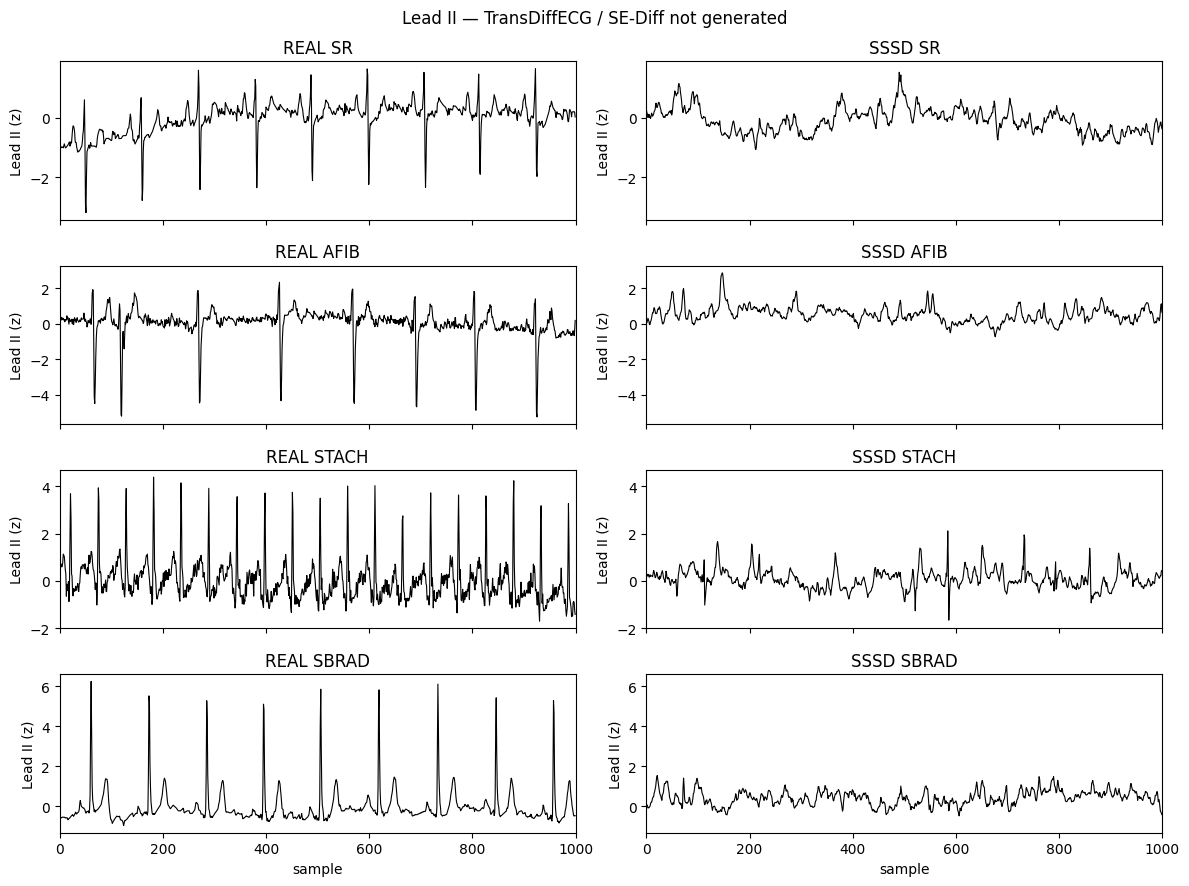

In [8]:
rng = np.random.default_rng(42)

def pick_real(c):
    idx = np.where(y_train == c)[0]
    return X_train[rng.choice(idx)]

fig, axes = plt.subplots(4, 2, figsize=(12, 9), sharex=True)
for i, name in enumerate(CLASS_ORDER):
    real = pick_real(i)
    syn = X_sssd[y_sssd == i][0]
    ymin = min(real[:,1].min(), syn[:,1].min())
    ymax = max(real[:,1].max(), syn[:,1].max())
    pad = 0.05 * (ymax - ymin + 1e-6)
    for j, (sig, title) in enumerate([(real, f"REAL {name}"), (syn, f"SSSD {name}")]):
        ax = axes[i, j]
        ax.plot(sig[:, 1], lw=0.8, color="k")
        ax.set_ylim(ymin - pad, ymax + pad)
        ax.set_title(title)
        ax.set_ylabel("Lead II (z)")
    axes[i, 0].set_xlim(0, 1000)
axes[-1, 0].set_xlabel("sample")
axes[-1, 1].set_xlabel("sample")
fig.suptitle("Lead II — TransDiffECG / SE-Diff not generated")
fig.tight_layout()
fig.savefig(ROOT/"plots"/"lead_ii_real_vs_sssd.png", dpi=120)
plt.show()

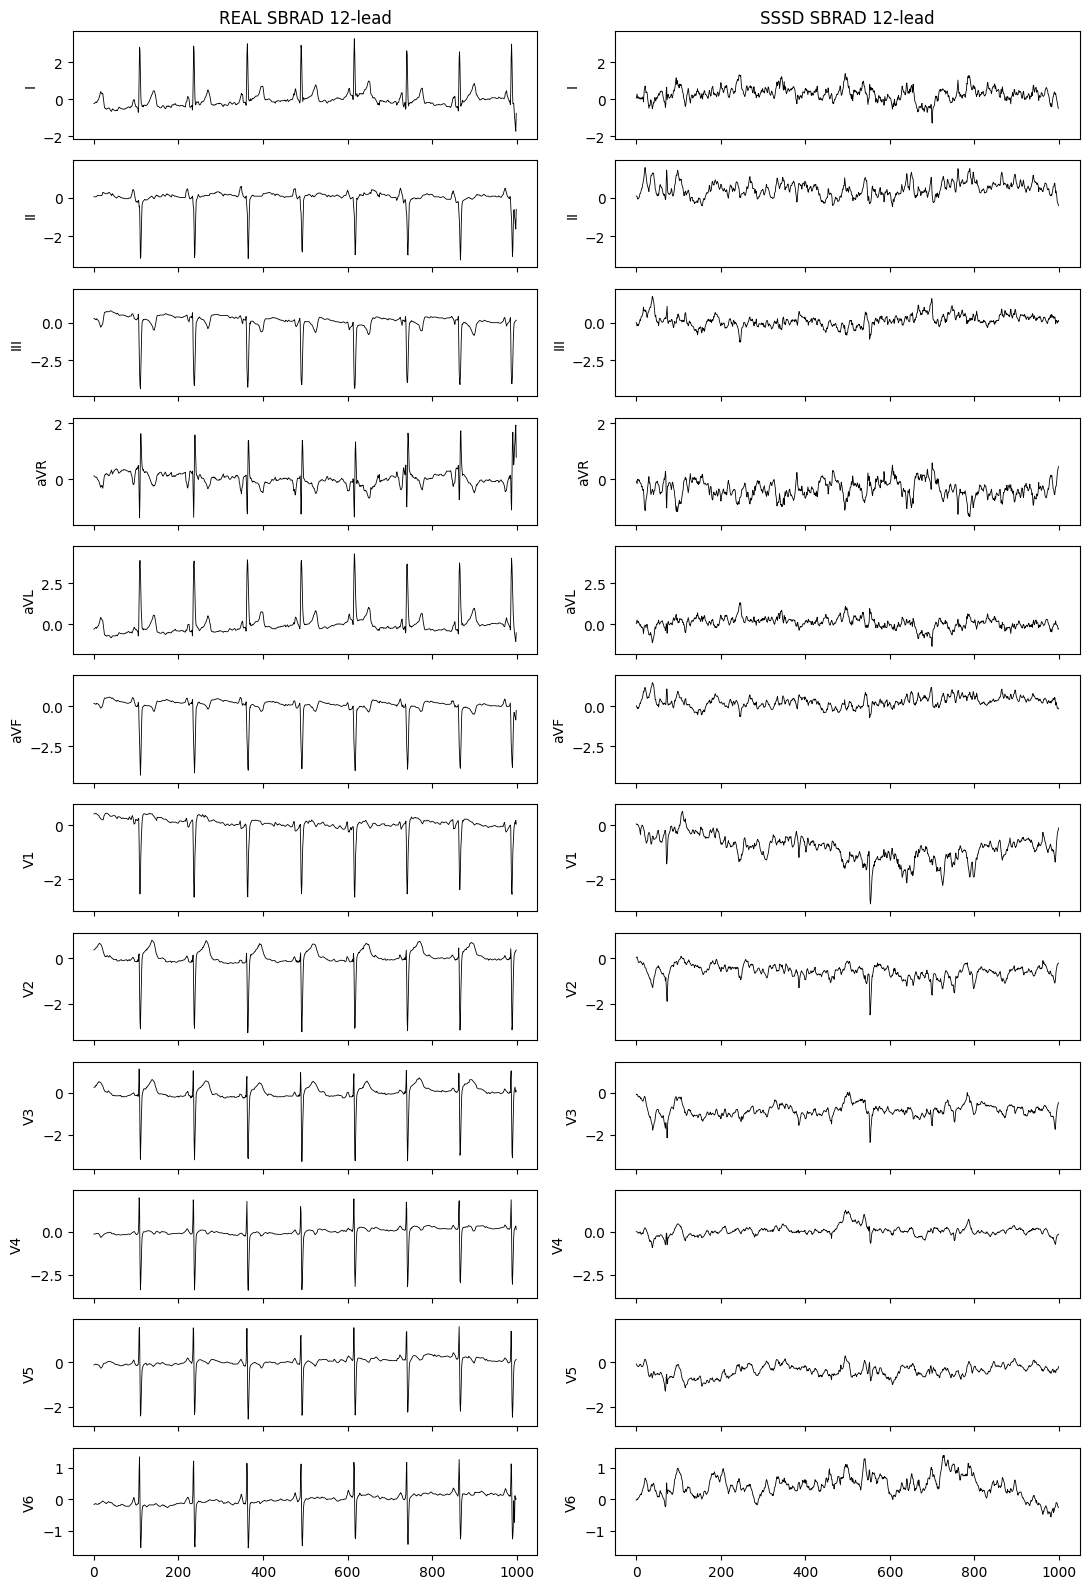

Visual: compare QRS regularity/rate only; no 'realistic' claim.


In [9]:
fig, axes = plt.subplots(12, 2, figsize=(11, 16), sharex=True)
c = 3  # SBRAD
real = pick_real(c)
syn = X_sssd[y_sssd == c][0]
for li, lead in enumerate(LEAD_ORDER_12):
    ymin = min(real[:,li].min(), syn[:,li].min())
    ymax = max(real[:,li].max(), syn[:,li].max())
    pad = 0.08 * (ymax - ymin + 1e-6)
    for j, sig in enumerate([real, syn]):
        ax = axes[li, j]
        ax.plot(sig[:, li], lw=0.6, color="k")
        ax.set_ylim(ymin - pad, ymax + pad)
        ax.set_ylabel(lead)
axes[0, 0].set_title("REAL SBRAD 12-lead")
axes[0, 1].set_title("SSSD SBRAD 12-lead")
fig.tight_layout()
fig.savefig(ROOT/"plots"/"sbrad_12lead_real_vs_sssd.png", dpi=110)
plt.show()
print("Visual: compare QRS regularity/rate only; no 'realistic' claim.")

## 9. Comparison tables

In [10]:
rows = [{
    "Generator": "SSSD-ECG-adapted",
    "Valid samples": f"{32*4 - sssd_sum['validity']['fail']}/128",
    "Params": n_params,
    "Training time (s)": round(train_sec, 1),
    "GPU memory train (GB)": round(peak_gb, 3),
    "GPU memory gen (GB)": round(sssd_gen_gb, 3),
    "Mean pairwise corr": round(sssd_sum["diversity"]["mean"], 3),
    "HR MAE vs train (bpm)": round(sssd_sum["hr_mae_vs_real"], 2),
    "Notes": "8x64 S4, T=200, 4000 train iters, 4-class one-hot, 8→12 reconstruction",
}, {
    "Generator": "TransDiffECG",
    "Valid samples": "N/A",
    "Params": "N/A",
    "Training time (s)": "N/A",
    "GPU memory train (GB)": "N/A",
    "GPU memory gen (GB)": "N/A",
    "Mean pairwise corr": "N/A",
    "HR MAE vs train (bpm)": "N/A",
    "Notes": "Not runnable: no public implementation",
}, {
    "Generator": "SE-Diff",
    "Valid samples": "N/A",
    "Params": "N/A",
    "Training time (s)": "N/A",
    "GPU memory train (GB)": "N/A",
    "GPU memory gen (GB)": "N/A",
    "Mean pairwise corr": "N/A",
    "HR MAE vs train (bpm)": "N/A",
    "Notes": "Not runnable: unpublished prerequisites / leakage / 4 GB",
}]
tab = pd.DataFrame(rows)
display(tab)
tab.to_csv(ROOT/"comparison_results"/"summary_table.csv", index=False)

hr_rows = []
for name, v in sssd_sum["hr_by_class"].items():
    hr_rows.append({
        "class": name,
        "SSSD_median_HR": v["syn_median_hr"],
        "REAL_median_HR": v["real_median_hr"],
        "abs_diff": v["abs_hr_diff"],
        "TransDiffECG": "N/A",
        "SE-Diff": "N/A",
    })
tab2 = pd.DataFrame(hr_rows)
display(tab2)
tab2.to_csv(ROOT/"comparison_results"/"hr_by_class.csv", index=False)
print("No composite overall quality score: undefined for this pilot.")

,Generator,Valid samples,Params,Training time (s),GPU memory train (GB),GPU memory gen (GB),Mean pairwise corr,HR MAE vs train (bpm),Notes
0,SSSD-ECG-adapted,128/128,1528072,405.2,0.983,0.146,0.142,29.22,"8x64 S4, T=200, 4000 train iters, 4-class one-..."
1,TransDiffECG,N/A,N/A,N/A,N/A,N/A,N/A,N/A,Not runnable: no public implementation
2,SE-Diff,N/A,N/A,N/A,N/A,N/A,N/A,N/A,Not runnable: unpublished prerequisites / leak...


,class,SSSD_median_HR,REAL_median_HR,abs_diff,TransDiffECG,SE-Diff
0,SR,130.570509,84.461313,46.109196,N/A,N/A
1,AFIB,132.425453,117.043121,15.382332,N/A,N/A
2,STACH,129.963933,111.111111,18.852822,N/A,N/A
3,SBRAD,132.841365,96.289837,36.551528,N/A,N/A


No composite overall quality score: undefined for this pilot.


## Generator Selection

Only **SSSD-ECG-adapted** produced a leakage-free, class-conditioned, 12-lead PTB-XL-format pilot pool on this hardware.

TransDiffECG and SE-Diff were **not** scored. Selecting SSSD is **not** because it was already coded; it is the only candidate that satisfies:

1. public architecture we can train from `X_train`/`y_train`
2. no pretrained PTB-XL weights
3. 4-class conditioning
4. 100 Hz / 10 s / 12-lead reconstruction
5. 4 GB VRAM feasibility

**Wording:** SSSD-ECG-adapted was selected as the most promising candidate for the subsequent PTB-XL augmentation study under our experimental and computational constraints. This 128-sample pilot is **not** enough to claim it is the best ECG generator in the literature.

In [11]:
selection = {
    "selected_generator": "SSSD-ECG-adapted",
    "pilot_not_sota_claim": True,
    "runnable": ["SSSD-ECG-adapted"],
    "not_runnable": ["TransDiffECG", "SE-Diff"],
    "reasons": {
        "validity": sssd_sum["validity"],
        "hr_mae_vs_real": sssd_sum["hr_mae_vs_real"],
        "diversity_mean_corr": sssd_sum["diversity"]["mean"],
        "hr_by_class": sssd_sum["hr_by_class"],
        "compute": {"train_sec": train_sec, "peak_gb": peak_gb, "params": n_params},
        "why_not_transdiff": transdiff_status["reason"],
        "why_not_sediff": sediff_status["reason"],
        "why_sssd": "Only leakage-free runnable generator matching PTB-XL four-class 12-lead 100 Hz setup on 4 GB VRAM.",
    },
    "ready_for_large_scale": True,
    "do_not_mass_generate_in_this_notebook": True,
    "large_scale_prep": {
        "checkpoint": str((ROOT/"sssd"/"checkpoint.pt").resolve()),
        "wavenet": ckpt["wavenet_config"],
        "diffusion": ckpt.get("diffusion_config"),
        "batch_size": 1,
        "use_amp": False,
        "recommended_next": "Increase sampling count for minority classes; keep train-only; then Week 5 quality assessment.",
    },
}
(ROOT/"metadata"/"selection.json").write_text(json.dumps(selection, indent=2), encoding="utf-8")
(ROOT/"comparison_results"/"sssd_metrics.json").write_text(json.dumps(sssd_sum, indent=2), encoding="utf-8")
print(json.dumps({k: selection[k] for k in ("selected_generator","runnable","not_runnable","ready_for_large_scale")}, indent=2))

{
  "selected_generator": "SSSD-ECG-adapted",
  "runnable": [
    "SSSD-ECG-adapted"
  ],
  "not_runnable": [
    "TransDiffECG",
    "SE-Diff"
  ],
  "ready_for_large_scale": true
}


## Outcome

SSSD-ECG-adapted → 128 balanced pilot  
TransDiffECG → not runnable  
SE-Diff → not runnable  

→ common evaluation on SSSD only  
→ **SSSD-ECG-adapted selected**  
→ READY FOR LARGE-SCALE GENERATION (next task; not run here)